# 03 · Modelling

**Question:** can alternative data (previous applications, repayment history) let a lender approve more
thin-file applicants **without taking on more risk**?

We compare three models on the same fixed splits (from notebook 02):

| Model | Features | Role |
|---|---|---|
| Logistic regression | all model inputs | simple, transparent baseline |
| **Conventional** LightGBM | application + credit bureau only | what a typical lender sees; the benchmark |
| **SecondLook** LightGBM | + previous applications, installments, POS, credit card | our model |

Splits: models train on `train`, early-stop on `valid`, are calibrated on `calib`, and **every reported number is on `test`**,
which nothing was tuned on. Gender and age are excluded from all models.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL
from secondlook.features import load_features
from secondlook.modeling import (
    ProfitAssumptions, approval_summary, cutoff_for_bad_rate, evaluate, feature_sets, fit_calibrator,
    predict_logistic, prepare, profit_curve, save_bundle, split_xy, train_lightgbm, train_logistic,
)

sns.set_theme(style="whitegrid", context="notebook")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {"Logistic": "#8C8C8C", "Conventional": "#4C72B0", "SecondLook": "#DD8452"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data and feature sets

In [2]:
df = prepare(load_features())
sets = feature_sets(df)
alt_cols = [c for c in sets["secondlook"] if c not in sets["conventional"]]
print(f"Conventional model: {len(sets['conventional'])} features")
print(f"SecondLook model:     {len(sets['secondlook'])} features (+{len(alt_cols)} alternative-data features)")

data = {}
for split in ["train", "valid", "calib", "test"]:
    X, y = split_xy(df, split, sets["secondlook"])
    data[split] = (X, y, df.loc[df["split"] == split, "THIN_FILE"].to_numpy().astype(bool))
    print(f"  {split:5s}: {len(y):>7,} applicants, default rate {y.mean():.2%}")

Conventional model: 142 features
SecondLook model:     165 features (+23 alternative-data features)
  train: 184,507 applicants, default rate 8.07%
  valid:  46,126 applicants, default rate 8.07%
  calib:  30,752 applicants, default rate 8.07%
  test :  46,126 applicants, default rate 8.07%


## 2. Train the three models

In [3]:
Xtr, ytr, _ = data["train"]
Xva, yva, _ = data["valid"]

t = time.time()
logit = train_logistic(Xtr, ytr)
print(f"Logistic regression trained in {time.time() - t:.0f}s")

t = time.time()
conv = train_lightgbm(Xtr[sets["conventional"]], ytr, Xva[sets["conventional"]], yva)
print(f"Conventional LightGBM: {conv.best_iteration_} trees in {time.time() - t:.0f}s")

t = time.time()
fair = train_lightgbm(Xtr, ytr, Xva, yva)
print(f"SecondLook LightGBM:     {fair.best_iteration_} trees in {time.time() - t:.0f}s")

Logistic regression trained in 12s


Conventional LightGBM: 795 trees in 20s


SecondLook LightGBM:     830 trees in 23s


In [4]:
def raw_scores(split):
    X, _, _ = data[split]
    return {
        "Logistic": predict_logistic(logit, X),
        "Conventional": conv.predict_proba(X[sets["conventional"]])[:, 1],
        "SecondLook": fair.predict_proba(X)[:, 1],
    }

raw = {split: raw_scores(split) for split in ["valid", "calib", "test"]}

## 3. Calibration
LightGBM ranks applicants well, but its raw scores are not exactly probabilities. We fit an isotonic
calibrator on the `calib` split, which no model has seen, so that "10% risk" really means about 1 in 10 default.

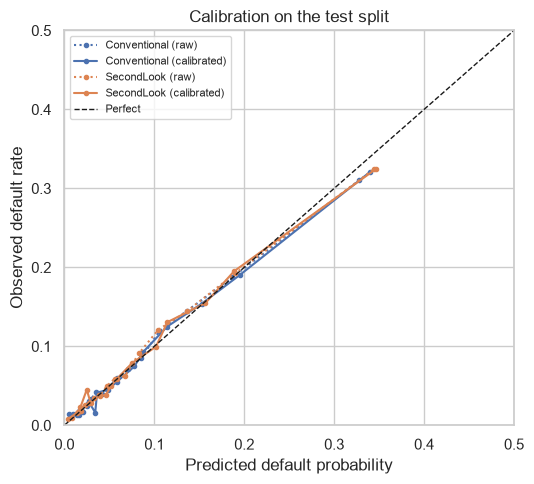

In [5]:
calibrators = {name: fit_calibrator(data["calib"][1], raw["calib"][name]) for name in COLORS}
scores = {split: {name: calibrators[name].predict(raw[split][name]) for name in COLORS} for split in ["valid", "test"]}

yte, thin_te = data["test"][1], data["test"][2]
fig, ax = plt.subplots(figsize=(5.5, 5))
for name in ["Conventional", "SecondLook"]:
    for label, p, ls in [("raw", raw["test"][name], ":"), ("calibrated", scores["test"][name], "-")]:
        frac, mean = calibration_curve(yte, p, n_bins=15, strategy="quantile")
        ax.plot(mean, frac, ls, marker="o", ms=3, color=COLORS[name], label=f"{name} ({label})")
ax.plot([0, 0.5], [0, 0.5], "k--", lw=1, label="Perfect")
ax.set_xlim(0, 0.5); ax.set_ylim(0, 0.5)
ax.set_xlabel("Predicted default probability"); ax.set_ylabel("Observed default rate")
ax.set_title("Calibration on the test split"); ax.legend(fontsize=8)
savefig("09_calibration")

## 4. Discrimination on the test split, overall and thin-file

In [6]:
results = pd.DataFrame({name: evaluate(yte, scores["test"][name], thin_te) for name in COLORS}).T
results = results[["roc_auc", "pr_auc", "brier", "thin_roc_auc", "thin_pr_auc"]]
results.columns = ["ROC-AUC", "PR-AUC", "Brier", "ROC-AUC (thin-file)", "PR-AUC (thin-file)"]
results.style.format("{:.4f}").highlight_max(subset=[c for c in results.columns if c != "Brier"], color="#FCE4D6")

,ROC-AUC,PR-AUC,Brier,ROC-AUC (thin-file),PR-AUC (thin-file)
Logistic,0.7580,0.2355,0.0677,0.7250,0.2360
Conventional,0.7628,0.2441,0.0675,0.7324,0.2532
SecondLook,0.7753,0.2579,0.0667,0.7545,0.2690


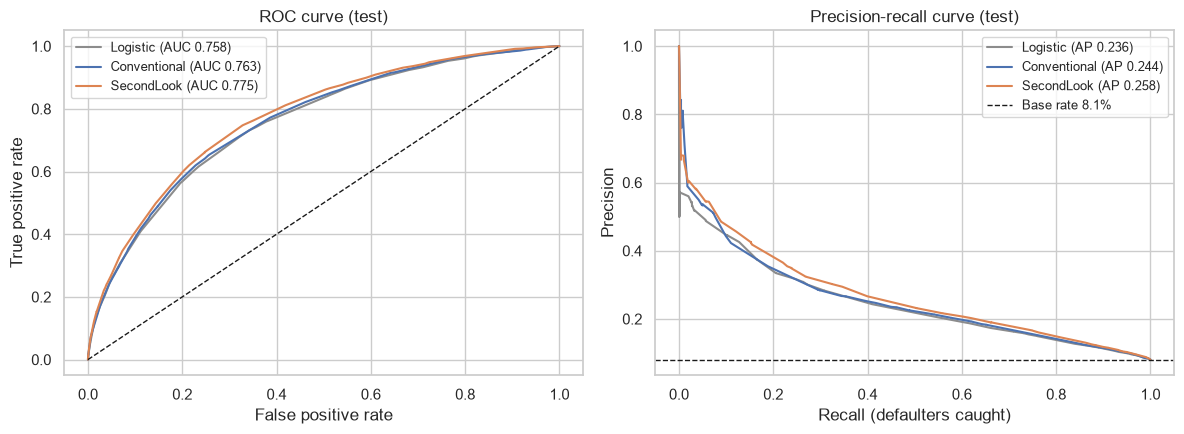

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, color in COLORS.items():
    p = scores["test"][name]
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(yte, p)
    axes[1].plot(rec, prec, color=color, label=f"{name} (AP {results.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(yte.mean(), color="k", ls="--", lw=1, label=f"Base rate {yte.mean():.1%}")
axes[1].set(title="Precision-recall curve (test)", xlabel="Recall (defaulters caught)", ylabel="Precision")
for ax in axes: ax.legend(fontsize=9)
savefig("10_roc_pr_curves")

## 5. The business result: more thin-file approvals at the same risk
A lender sets a **risk appetite**: the default rate it accepts among approved loans. We fix that at 5%
(well below the 8.07% base rate), choose each model's cutoff on the **validation** split so that its approved
book meets the target, then apply that cutoff to the untouched **test** split.

In [8]:
TARGET_BAD_RATE = 0.05
yva, thin_va = data["valid"][1], data["valid"][2]

rows = {}
for name in COLORS:
    cutoff = cutoff_for_bad_rate(yva, scores["valid"][name], TARGET_BAD_RATE)
    rows[name] = {"cutoff": cutoff, **approval_summary(yte, scores["test"][name], cutoff, thin_te)}
appr = pd.DataFrame(rows).T
appr.style.format({
    "cutoff": "{:.3f}", "approval_rate": "{:.1%}", "bad_rate_approved": "{:.2%}",
    "thin_approval_rate": "{:.1%}", "thin_bad_rate_approved": "{:.2%}",
    "thin_good_approved": "{:,.0f}", "thin_good_total": "{:,.0f}",
})

,cutoff,approval_rate,bad_rate_approved,thin_approval_rate,thin_bad_rate_approved,thin_good_approved,thin_good_total
Logistic,0.134,86.4%,5.51%,81.0%,6.88%,"4,981","5,934"
Conventional,0.146,84.1%,5.17%,77.7%,6.62%,"4,793","5,934"
SecondLook,0.158,87.9%,5.52%,83.0%,6.92%,"5,100","5,934"


In [9]:
gain_all = appr.loc["SecondLook", "approval_rate"] - appr.loc["Conventional", "approval_rate"]
gain_thin = appr.loc["SecondLook", "thin_approval_rate"] - appr.loc["Conventional", "thin_approval_rate"]
extra_good_thin = int(appr.loc["SecondLook", "thin_good_approved"] - appr.loc["Conventional", "thin_good_approved"])
n_test, n_thin = len(yte), int(thin_te.sum())
print(f"At a {TARGET_BAD_RATE:.0%} risk appetite, on {n_test:,} test applicants ({n_thin:,} thin-file):")
print(f"  Default rate among approved (target {TARGET_BAD_RATE:.0%}): "
      f"{appr.loc['Conventional', 'bad_rate_approved']:.2%} vs {appr.loc['SecondLook', 'bad_rate_approved']:.2%}")
print(f"  Overall approval rate:   {appr.loc['Conventional', 'approval_rate']:.1%} -> {appr.loc['SecondLook', 'approval_rate']:.1%} ({gain_all:+.1%} points)")
print(f"  Thin-file approval rate: {appr.loc['Conventional', 'thin_approval_rate']:.1%} -> {appr.loc['SecondLook', 'thin_approval_rate']:.1%} ({gain_thin:+.1%} points)")
print(f"  Extra thin-file applicants approved who repaid: {extra_good_thin:+,} "
      f"(about {extra_good_thin / n_thin * 1000:.0f} per 1,000 thin-file applicants)")

At a 5% risk appetite, on 46,126 test applicants (6,603 thin-file):
  Default rate among approved (target 5%): 5.17% vs 5.52%
  Overall approval rate:   84.1% -> 87.9% (+3.8% points)
  Thin-file approval rate: 77.7% -> 83.0% (+5.2% points)
  Extra thin-file applicants approved who repaid: +307 (about 46 per 1,000 thin-file applicants)


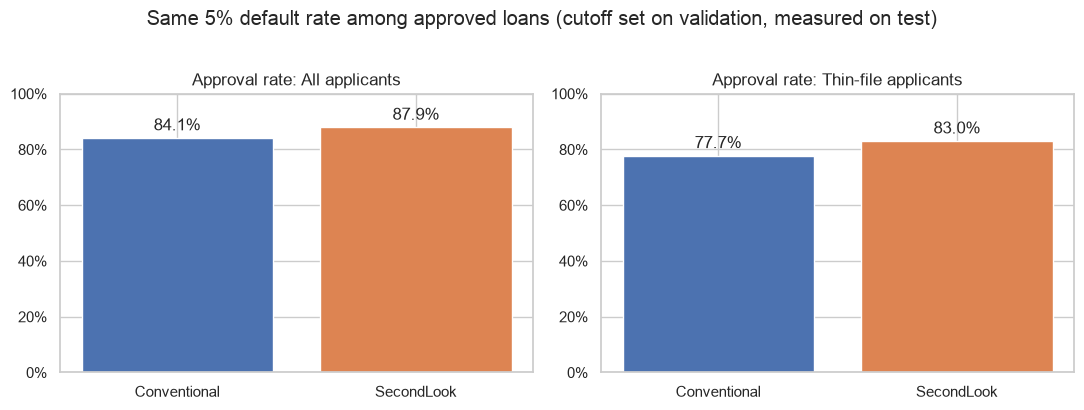

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot = appr.loc[["Conventional", "SecondLook"]]
for ax, (col, title) in zip(axes, [("approval_rate", "All applicants"), ("thin_approval_rate", "Thin-file applicants")]):
    bars = ax.bar(plot.index, plot[col], color=[COLORS[n] for n in plot.index])
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in plot[col]], padding=3)
    ax.set_title(f"Approval rate: {title}"); ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle(f"Same {TARGET_BAD_RATE:.0%} default rate among approved loans (cutoff set on validation, measured on test)", y=1.02)
savefig("11_approvals_gain")

The single 5% point depends on one cutoff. The curve below sweeps **every** cutoff on the test split: for any
default rate the lender is willing to accept on its approved book, how many thin-file applicants get approved?
A curve that sits higher means more thin-file approvals at the same risk.

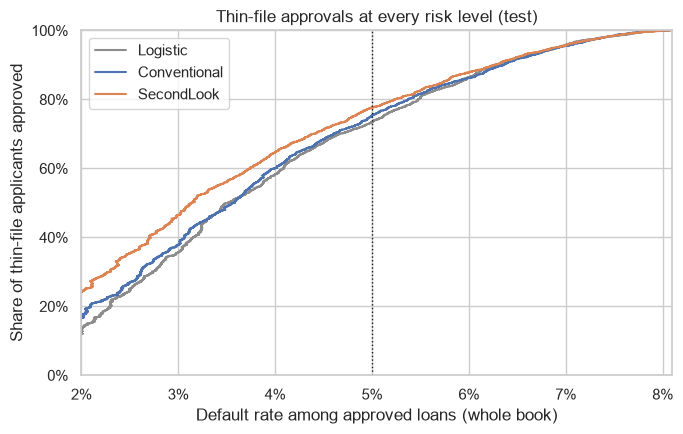

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in ["Logistic", "Conventional", "SecondLook"]:
    p = scores["test"][name]
    order = np.argsort(p, kind="stable")
    approved_bad = np.cumsum(yte[order]) / np.arange(1, len(yte) + 1)
    thin_approved = np.cumsum(thin_te[order]) / thin_te.sum()
    keep = np.arange(len(yte)) >= 2000  # skip the noisy start of the curve
    ax.plot(approved_bad[keep], thin_approved[keep], color=COLORS[name], label=name)
ax.axvline(TARGET_BAD_RATE, color="k", ls=":", lw=1)
ax.set(xlim=(0.02, 0.081), ylim=(0, 1), xlabel="Default rate among approved loans (whole book)",
       ylabel="Share of thin-file applicants approved", title="Thin-file approvals at every risk level (test)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend()
savefig("11b_thin_file_tradeoff")

## 6. Profit-based cutoff
The 5% risk appetite above is a policy choice. Alternatively, pick the cutoff that **maximises expected profit**.
Simple unit economics, as a share of the loan amount (illustrative; change them in `ProfitAssumptions`):

- repaid loan: **+10%** net margin over its life
- defaulted loan: **−65%** (loss given default)

So approving is worth it while the probability of default is below 0.10 / (0.10 + 0.65) ≈ **13.3%**.
The cutoff is chosen on `valid` and profit is reported on `test`.

Profit if every test applicant were approved: 1,193.6M


,cutoff,approval_rate,bad_rate_approved,thin_approval_rate,profit_m
Conventional,0.147,84.1%,5.17%,77.7%,"1,482.4"
SecondLook,0.125,82.5%,4.86%,75.9%,"1,504.6"


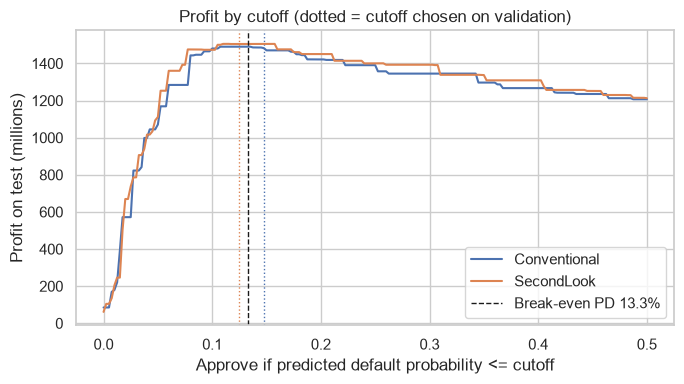

In [12]:
econ = ProfitAssumptions()
amount_va = df.loc[df["split"] == "valid", "AMT_CREDIT"].to_numpy()
amount_te = df.loc[df["split"] == "test", "AMT_CREDIT"].to_numpy()

curves, best = {}, {}
for name in ["Conventional", "SecondLook"]:
    cv = profit_curve(yva, scores["valid"][name], amount_va, econ)
    best[name] = cv.loc[cv["profit"].idxmax(), "cutoff"]
    curves[name] = profit_curve(yte, scores["test"][name], amount_te, econ)

fig, ax = plt.subplots(figsize=(7, 4))
for name, cv in curves.items():
    ax.plot(cv["cutoff"], cv["profit"] / 1e6, color=COLORS[name], label=name)
    ax.axvline(best[name], color=COLORS[name], ls=":", lw=1)
ax.axvline(econ.breakeven_pd, color="k", ls="--", lw=1, label=f"Break-even PD {econ.breakeven_pd:.1%}")
ax.set(xlabel="Approve if predicted default probability <= cutoff", ylabel="Profit on test (millions)",
       title="Profit by cutoff (dotted = cutoff chosen on validation)")
ax.legend()
savefig("12_profit_curve")

profit = pd.DataFrame({
    name: {"cutoff": best[name], **approval_summary(yte, scores["test"][name], best[name], thin_te),
           "profit_m": curves[name].set_index("cutoff").loc[best[name], "profit"] / 1e6}
    for name in ["Conventional", "SecondLook"]}).T
approve_all = profit_curve(yte, np.zeros_like(yte, dtype=float), amount_te, econ, cutoffs=[0.0])["profit"].iloc[0] / 1e6
print(f"Profit if every test applicant were approved: {approve_all:,.1f}M")
profit[["cutoff", "approval_rate", "bad_rate_approved", "thin_approval_rate", "profit_m"]].style.format(
    {"cutoff": "{:.3f}", "approval_rate": "{:.1%}", "bad_rate_approved": "{:.2%}", "thin_approval_rate": "{:.1%}", "profit_m": "{:,.1f}"})

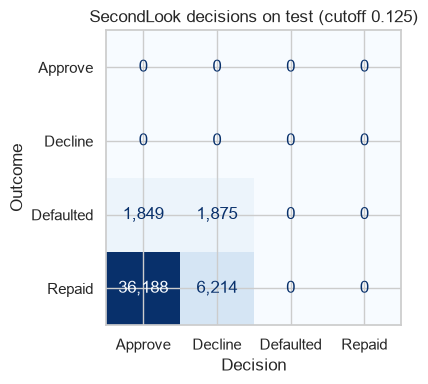

In [13]:
cutoff = best["SecondLook"]
approve = scores["test"]["SecondLook"] <= cutoff
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    np.where(yte == 1, "Defaulted", "Repaid"), np.where(approve, "Approve", "Decline"),
    labels=None, ax=ax, colorbar=False, cmap="Blues", values_format=",")
ax.set(title=f"SecondLook decisions on test (cutoff {cutoff:.3f})", xlabel="Decision", ylabel="Outcome")
savefig("13_confusion_matrix")

## 7. What drives the SecondLook model?

Share of total gain from alternative-data features: 19.1%


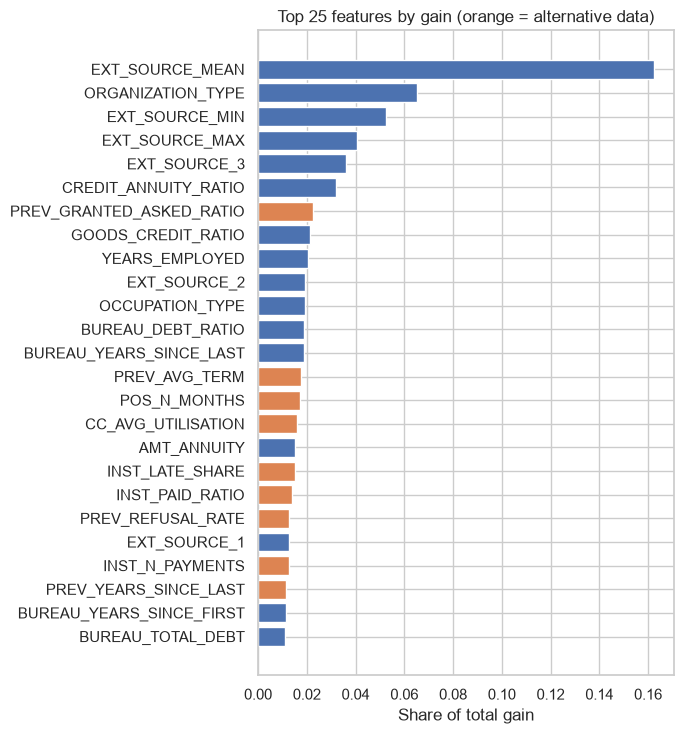

In [14]:
imp = pd.Series(fair.booster_.feature_importance("gain"), index=fair.booster_.feature_name())
imp = (imp / imp.sum()).sort_values(ascending=False)
top = imp.head(25).sort_values()
fig, ax = plt.subplots(figsize=(7, 7.5))
ax.barh(top.index, top.values, color=[COLORS["SecondLook"] if c in alt_cols else COLORS["Conventional"] for c in top.index])
ax.set(title="Top 25 features by gain (orange = alternative data)", xlabel="Share of total gain")
savefig("14_feature_importance")
print(f"Share of total gain from alternative-data features: {imp[imp.index.isin(alt_cols)].sum():.1%}")

## 8. Save the models

In [15]:
categories = {c: list(df[c].cat.categories) for c in sets["secondlook"] if isinstance(df[c].dtype, pd.CategoricalDtype)}
for name, model, cols in [("secondlook_lgbm", fair, sets["secondlook"]), ("conventional_lgbm", conv, sets["conventional"])]:
    key = "SecondLook" if name.startswith("secondlook") else "Conventional"
    save_bundle(name, model, calibrators[key], cols, categories, {
        "test_metrics": results.loc[key].to_dict(),
        "risk_appetite": {"target_bad_rate": TARGET_BAD_RATE, **appr.loc[key].to_dict()},
        "profit_cutoff": float(best[key]),
        "profit_assumptions": {"margin": econ.margin, "lgd": econ.lgd},
        "best_iteration": int(model.best_iteration_),
    })
print("Saved to models/:", sorted(p.name for p in (FIGURES_DIR.parents[1] / "models").glob("*_lgbm*")))

Saved to models/: ['conventional_lgbm.joblib', 'conventional_lgbm_meta.json', 'secondlook_lgbm.joblib', 'secondlook_lgbm_meta.json', 'secondlook_seq_lgbm.joblib', 'secondlook_seq_lgbm_meta.json']


## Takeaways

All numbers are on the untouched test split (46,126 applicants, 6,603 thin-file). Since the notebook 08 audit, the model
no longer uses family status, number of children or `EMPLOYED_AGE_RATIO` (`config.EXCLUDED_INPUTS`); accuracy did not change.

1. **Alternative data helps most where it should.** SecondLook beats the conventional model overall (ROC-AUC 0.7753 vs 0.7628), and the gain is almost twice as large on thin-file applicants (0.7545 vs 0.7324).
2. **More thin-file approvals at the same risk.** Holding the default rate on the whole approved book fixed (the trade-off curve), SecondLook approves **8.6 points more** thin-file applicants at 3% (46.5% vs 37.9%), 4.6 points more at 4% (64.7% vs 60.1%) and 2.4 points more at 5% (77.7% vs 75.3%). The gain narrows as the lender loosens, because both models then approve most applicants.
3. **Higher profit with a safer book.** At the profit-maximising cutoff (illustrative economics: +10% margin if repaid, −65% loss if defaulted), SecondLook earns 1,504.6M vs 1,482.4M on the test applicants (+1.5%), with a lower default rate on approved loans (4.86% vs 5.17%). Both beat approving everyone (1,194M).
4. **Scores are trustworthy as probabilities.** After isotonic calibration on the held-out `calib` split, predicted and observed default rates line up closely (Brier 0.0667).
5. **What drives it.** The external scores still dominate, but alternative-data features carry 19.1% of the model's total gain: share of the requested amount granted on previous loans, previous loan terms, POS history, card utilisation and late installment payments.
6. **Honest caveats.** The overall AUC gain is modest (+0.0125). The cutoff chosen on validation for a 5% target lands at 5.5% on test for SecondLook (5.2% for the conventional model): isotonic calibration is a step function, so many applicants share the exact score at the cutoff and a small shift moves a block of approvals. So the "+307 thin-file good borrowers approved" from the single cutoff partly reflects a looser book; the trade-off curve in point 2 is the fair comparison. And the profit figures depend on the assumed margin and loss rate, so we show the full curve rather than one number.

**Next:** notebook 04 explains individual decisions (SHAP) and suggests a path to approval; notebooks 06–07 test whether reject inference and the sequence encoder widen the thin-file gap further.